# Automatic Short Answer Grading: Comparative Evaluation of Three Computational Paradigms

**Research Project:** Automatic Short Answer Grading using Semantic and Dependency Analysis  
**Repository:** `proposition-level-asag`  
**Dataset:** Official UNT Computer Science Short Answer Dataset v2.0 (*Mohler, Bunescu, & Mihalcea, 2011*)  
**Evaluation Target:** $N = 2,273$ active student responses across 81 computer science questions  
**Ground Truth:** Average human rating (`human_score`, continuous scale: $0.0 - 5.0$, mean: $4.1839$)  

---

### Research Context & Hypotheses

This notebook conducts a rigorous, empirical comparison of three distinct Automatic Short Answer Grading (ASAG) engines:

1. **Model 1 — TF-IDF + Cosine Similarity Baseline:**  
   A classical bag-of-words vector space model measuring lexical co-occurrence.
2. **Model 2 — Semantic/Dependency-Based ASAG:**  
   A clausal dependency-triple system directly inspired by Basak, Naskar, and Gelbukh (2019), extracting $(Subject, Relation, Object)$ structures and matching via WordNet path similarity.
3. **Model 3 — Proposition-Level ASAG with Additional-Information Analysis:**  
   An interpretable proposition-level engine that incorporates canonical reference fragment recovery, core paraphrase alignment, positive-evidence contradiction checking, and an epistemic four-way classification layer (`CORRECT_ADDITIONAL`, `IRRELEVANT`, `INCORRECT`, `UNCERTAIN`).

#### Core Research Question:
> *"Can an interpretable proposition-level extension of a classical semantic/dependency-based ASAG system evaluate unmatched student information as correct additional, irrelevant, or incorrect information, and does incorporating this evaluation improve agreement with human grading?"*

This notebook independently recalculates all statistical metrics, visualizes score distributions, analyzes calibration and residuals, evaluates performance across sentential and non-sentential reference subsets, and examines genuine qualitative case studies from the benchmark.

## 1. Environment Setup & Artifact Verification

In [1]:
import os
import json
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, cohen_kappa_score

# Set matplotlib style for publication-quality figures
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 150
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

# File paths
PREDICTIONS_PATH = "evaluation/results/task8_benchmark/mohler_task8_evaluation_predictions.csv"
SUMMARY_PATH = "evaluation/results/task8_benchmark/mohler_task8_evaluation_summary.json"

assert os.path.exists(PREDICTIONS_PATH), f"Predictions artifact not found at {PREDICTIONS_PATH}"
assert os.path.exists(SUMMARY_PATH), f"Summary artifact not found at {SUMMARY_PATH}"

print(f"Verified benchmark predictions: {PREDICTIONS_PATH}")
print(f"Verified benchmark summary:     {SUMMARY_PATH}")
print("Setup complete.")

Matplotlib is building the font cache; this may take a moment.


Verified benchmark predictions: evaluation/results/task8_benchmark/mohler_task8_evaluation_predictions.csv
Verified benchmark summary:     evaluation/results/task8_benchmark/mohler_task8_evaluation_summary.json
Setup complete.


## 2. Dataset Ingestion & Integrity Audit

We load the verified Task 8 predictions dataset and confirm its schema and sample counts.

The dataset includes:
- **Identifier fields:** `question_id`, `assignment`, `student_index`
- **Textual fields:** `question_text`, `reference_text`, `student_text`
- **Target ground truth:** `human_score` (continuous scale $[0.0, 5.0]$)
- **Model predictions:**
  - `v0_grade`: Model 1 (TF-IDF + Cosine Similarity Baseline)
  - `v1_grade`: Model 2 (Semantic/Dependency-Based ASAG)
  - `v5_full_grade`: Model 3 (Proposition-Level ASAG with Additional-Information Analysis)
- **Diagnostic flags:** `has_non_sentential_ref`, `recovered_core_count`, `guarded_contra_count`, proposition category counts.

In [2]:
df = pd.read_csv(PREDICTIONS_PATH, dtype={'question_id': str, 'assignment': str})

print("Dataset Dimensions:", df.shape)
print("\nColumns:", list(df.columns))

# Verify active sample count exactly matches benchmark specification
assert len(df) == 2273, f"Expected 2273 records, found {len(df)}"

# Display first 3 rows focusing on model outputs
display_cols = ['question_id', 'human_score', 'v0_grade', 'v1_grade', 'v5_full_grade', 'has_non_sentential_ref']
display(df[display_cols].head(3))

# Summary statistics for ground truth and model predictions
print("\nScore Distribution Summary (Scale 0.0 - 5.0):")
stats_df = df[['human_score', 'v0_grade', 'v1_grade', 'v5_full_grade']].describe().T
stats_df['median'] = df[['human_score', 'v0_grade', 'v1_grade', 'v5_full_grade']].median()
display(stats_df[['mean', 'std', 'min', 'median', 'max']])

Dataset Dimensions: (2273, 25)

Columns: ['question_id', 'assignment', 'student_index', 'question_text', 'reference_text', 'student_text', 'human_score', 'v0_grade', 'v1_grade', 'task7_v5_grade', 'v5_core_grade', 'v5_full_grade', 'delta_t8_vs_t7', 'delta_full_vs_core', 'has_non_sentential_ref', 'status', 'base_coverage', 'recovered_core_count', 'guarded_contra_count', 'has_core_invalidation', 'matched_count', 'correct_additional_count', 'incorrect_count', 'irrelevant_count', 'uncertain_count']


,question_id,human_score,v0_grade,v1_grade,v5_full_grade,has_non_sentential_ref
0,1.1,3.5,0.9779,0.0,0.0000,True
1,1.1,5.0,1.6445,0.0,4.7583,True
2,1.1,4.0,2.8458,0.0,4.9167,True



Score Distribution Summary (Scale 0.0 - 5.0):


,mean,std,min,median,max
human_score,4.183898,1.096596,0.0,4.5000,5.0
v0_grade,1.531645,1.157225,0.0,1.3985,5.0
v1_grade,0.392544,1.011955,0.0,0.0000,5.0
v5_full_grade,0.885957,1.514166,0.0,0.0000,5.0


## 3. Independent Metrics Recalculation & Primary Benchmark Comparison

To verify empirical integrity, we independently compute all standard ASAG evaluation metrics:
- **MAE (Mean Absolute Error):** Average magnitude of absolute errors on the 5-point scale.
- **RMSE (Root Mean Squared Error):** Square root of mean squared prediction errors.
- **Pearson $r$:** Linear correlation with ground truth human scores.
- **Spearman $\rho$:** Monotonic rank-order correlation.
- **Quadratic Weighted Kappa (QWK):** Agreement across discrete 6-class integer bins ($\{0, 1, 2, 3, 4, 5\}$).

In [3]:
def compute_asag_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    
    # Check for constant input to avoid division by zero in correlation
    if np.all(y_pred == y_pred.iloc[0]) or np.all(y_true == y_true.iloc[0]):
        pearson_r = 0.0
        spearman_rho = 0.0
    else:
        pearson_r, _ = stats.pearsonr(y_true, y_pred)
        spearman_rho, _ = stats.spearmanr(y_true, y_pred)
    
    # Discretize continuous scores to integer bins for QWK [0, 5]
    y_true_disc = np.clip(np.round(y_true), 0, 5).astype(int)
    y_pred_disc = np.clip(np.round(y_pred), 0, 5).astype(int)
    qwk = cohen_kappa_score(y_true_disc, y_pred_disc, weights='quadratic')
    
    return {
        'MAE': mae,
        'RMSE': rmse,
        'Pearson r': pearson_r,
        'Spearman rho': spearman_rho,
        'QWK': qwk,
        'Predicted Mean': np.mean(y_pred)
    }

models_dict = {
    'Model 1 — TF-IDF + Cosine Similarity Baseline': df['v0_grade'],
    'Model 2 — Semantic/Dependency-Based ASAG': df['v1_grade'],
    'Model 3 — Proposition-Level ASAG with Additional-Information Analysis': df['v5_full_grade']
}

results = []
for name, preds in models_dict.items():
    m = compute_asag_metrics(df['human_score'], preds)
    m['Model'] = name
    results.append(m)

metrics_df = pd.DataFrame(results).set_index('Model')
display(metrics_df.round(4))

# Verify against official summary JSON
with open(SUMMARY_PATH, 'r') as f:
    summary_json = json.load(f)
official_full = summary_json['subsets']['full_active']['models']

print("\nVerification against Task 8 Summary JSON:")
print(f"Model 1 (V0) Official Pearson: {official_full['V0']['metrics']['pearson_r']:.4f} | Computed: {metrics_df.loc['Model 1 — TF-IDF + Cosine Similarity Baseline', 'Pearson r']:.4f}")
print(f"Model 2 (V1) Official Pearson: {official_full['V1']['metrics']['pearson_r']:.4f} | Computed: {metrics_df.loc['Model 2 — Semantic/Dependency-Based ASAG', 'Pearson r']:.4f}")
print(f"Model 3 (V5) Official Pearson: {official_full['V5_Full']['metrics']['pearson_r']:.4f} | Computed: {metrics_df.loc['Model 3 — Proposition-Level ASAG with Additional-Information Analysis', 'Pearson r']:.4f}")

,MAE,RMSE,Pearson r,Spearman rho,QWK,Predicted Mean
Model,,,,,,
Model 1 — TF-IDF + Cosine Similarity Baseline,2.6571,2.9178,0.4184,0.4424,0.1151,1.5316
Model 2 — Semantic/Dependency-Based ASAG,3.8041,4.0365,0.1383,0.1179,0.0180,0.3925
Model 3 — Proposition-Level ASAG with Additional-Information Analysis,3.3358,3.6745,0.2616,0.2820,0.0614,0.8860



Verification against Task 8 Summary JSON:
Model 1 (V0) Official Pearson: 0.4184 | Computed: 0.4184
Model 2 (V1) Official Pearson: 0.1383 | Computed: 0.1383
Model 3 (V5) Official Pearson: 0.2616 | Computed: 0.2616


## 4. Benchmark Performance Visualizations

We plot the comparative performance metrics across all three systems. 

**Key Takeaways:**
1. **Model 1 (TF-IDF)** achieves the highest Pearson ($r = 0.4184$) and lowest MAE ($2.6571$).
2. **Model 3 (Proposition ASAG)** substantially outperforms **Model 2 (Base ASAG)**, nearly doubling Pearson correlation ($0.2616$ vs. $0.1383$) and reducing MAE from $3.8041$ to $3.3358$.
3. However, Model 3 remains behind Model 1 in rank correlation.

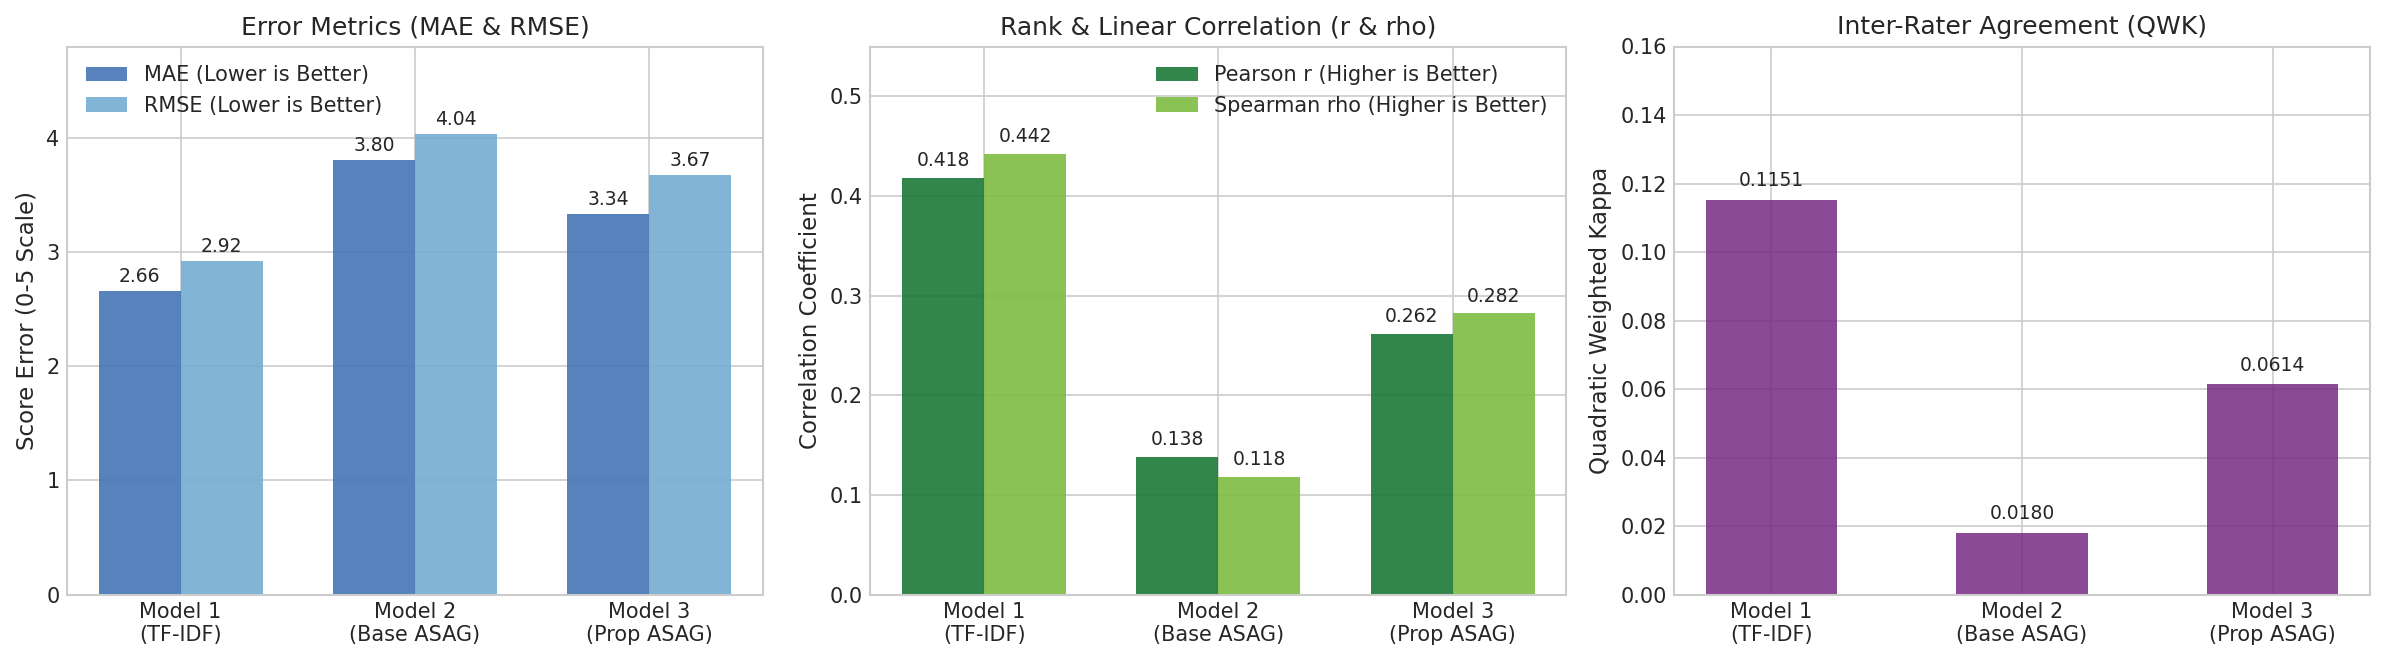

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

model_short_labels = ['Model 1\n(TF-IDF)', 'Model 2\n(Base ASAG)', 'Model 3\n(Prop ASAG)']
colors = ['#2b5c8f', '#d95f02', '#2ca02c']

# 1. Error Metrics (MAE and RMSE)
x = np.arange(len(model_short_labels))
width = 0.35
axes[0].bar(x - width/2, metrics_df['MAE'], width, label='MAE (Lower is Better)', color='#4575b4', alpha=0.9)
axes[0].bar(x + width/2, metrics_df['RMSE'], width, label='RMSE (Lower is Better)', color='#74add1', alpha=0.9)
axes[0].set_title('Error Metrics (MAE & RMSE)')
axes[0].set_xticks(x)
axes[0].set_xticklabels(model_short_labels)
axes[0].set_ylabel('Score Error (0-5 Scale)')
axes[0].set_ylim(0, 4.8)
axes[0].legend()
for i in range(len(model_short_labels)):
    axes[0].text(x[i] - width/2, metrics_df['MAE'].iloc[i] + 0.08, f"{metrics_df['MAE'].iloc[i]:.2f}", ha='center', fontsize=9)
    axes[0].text(x[i] + width/2, metrics_df['RMSE'].iloc[i] + 0.08, f"{metrics_df['RMSE'].iloc[i]:.2f}", ha='center', fontsize=9)

# 2. Correlation Metrics (Pearson r & Spearman rho)
axes[1].bar(x - width/2, metrics_df['Pearson r'], width, label='Pearson r (Higher is Better)', color='#1b7837', alpha=0.9)
axes[1].bar(x + width/2, metrics_df['Spearman rho'], width, label='Spearman rho (Higher is Better)', color='#7fbc41', alpha=0.9)
axes[1].set_title('Rank & Linear Correlation (r & rho)')
axes[1].set_xticks(x)
axes[1].set_xticklabels(model_short_labels)
axes[1].set_ylabel('Correlation Coefficient')
axes[1].set_ylim(0, 0.55)
axes[1].legend()
for i in range(len(model_short_labels)):
    axes[1].text(x[i] - width/2, metrics_df['Pearson r'].iloc[i] + 0.012, f"{metrics_df['Pearson r'].iloc[i]:.3f}", ha='center', fontsize=9)
    axes[1].text(x[i] + width/2, metrics_df['Spearman rho'].iloc[i] + 0.012, f"{metrics_df['Spearman rho'].iloc[i]:.3f}", ha='center', fontsize=9)

# 3. Agreement Metric (Quadratic Weighted Kappa)
axes[2].bar(x, metrics_df['QWK'], width*1.5, color='#762a83', alpha=0.85)
axes[2].set_title('Inter-Rater Agreement (QWK)')
axes[2].set_xticks(x)
axes[2].set_xticklabels(model_short_labels)
axes[2].set_ylabel('Quadratic Weighted Kappa')
axes[2].set_ylim(0, 0.16)
for i in range(len(model_short_labels)):
    axes[2].text(x[i], metrics_df['QWK'].iloc[i] + 0.004, f"{metrics_df['QWK'].iloc[i]:.4f}", ha='center', fontsize=9)

plt.tight_layout()
plt.show()

## 5. Score Distribution Analysis & The Underprediction Phenomenon

A defining characteristic of rule-based structural ASAG is systematic score underprediction.

- **Human Graders** exhibit an average score of **4.1839 / 5.0** (with a median of 4.5), reflecting typical classroom performance where most students write mostly correct answers.
- **Model 1 (TF-IDF)** achieves a mean prediction of **1.5316**.
- **Model 2 (Base ASAG)** collapses to a mean of **0.3925** (with over 75% of answers scored at 0.0).
- **Model 3 (Proposition ASAG)** improves the mean to **0.8860**, recovering partial credit through canonical reference representations.

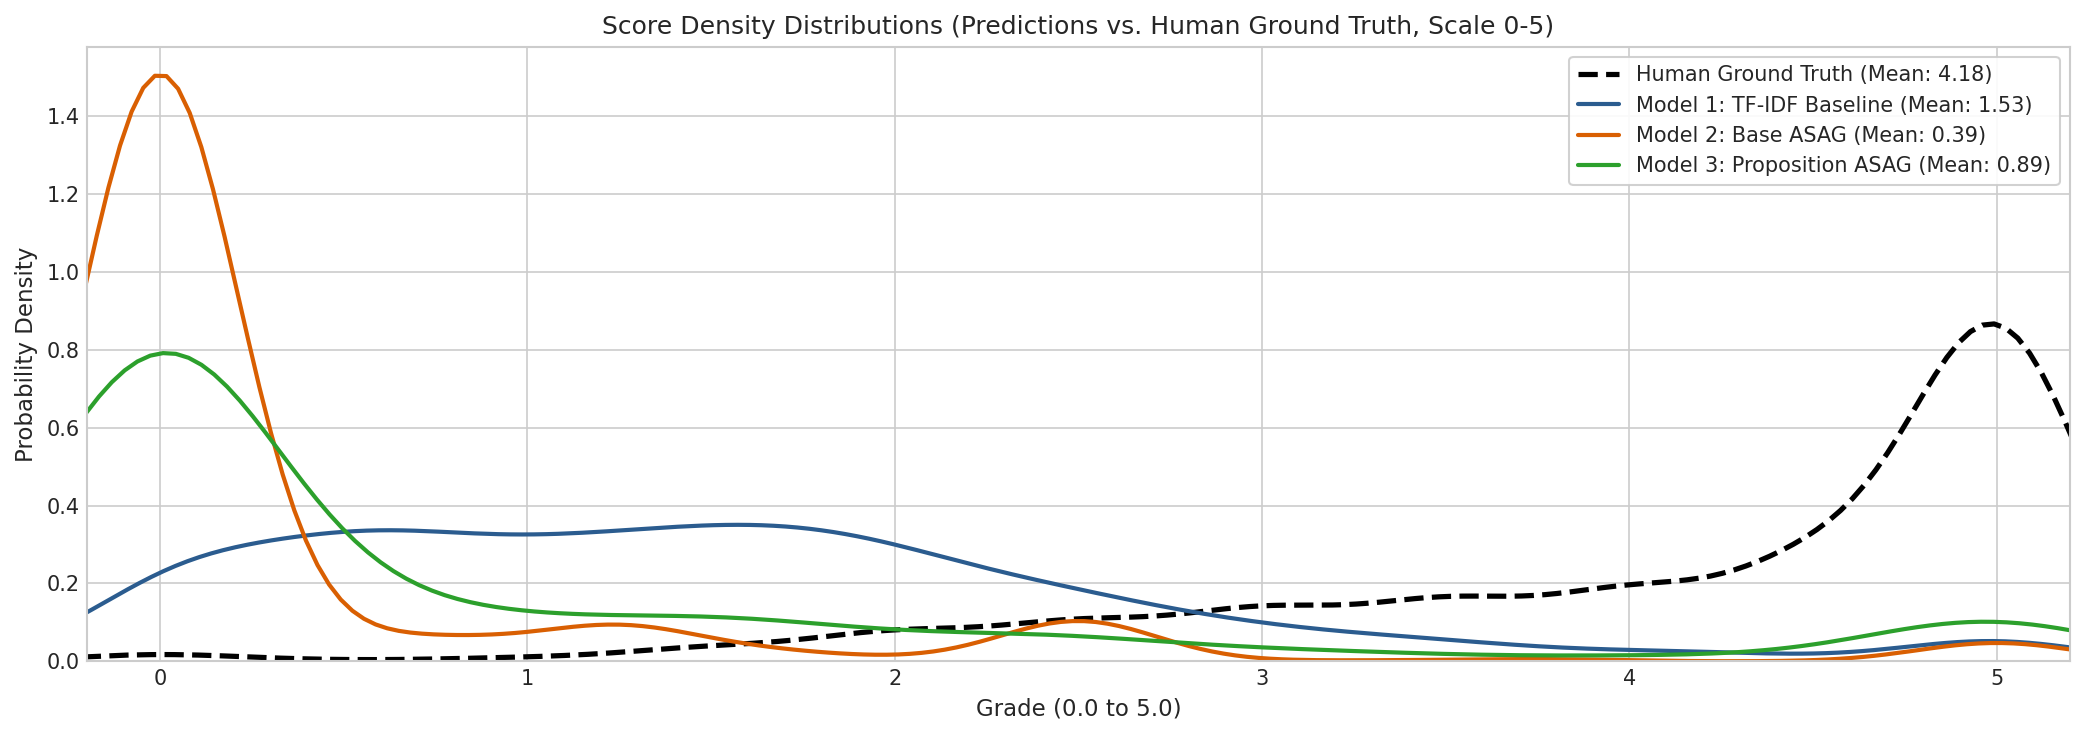

Percentage of answers receiving 0.0 grade:
  Model 1 (TF-IDF Baseline):      8.49%
  Model 2 (Base ASAG):            81.39%  <-- Catastrophic zero-floor defect
  Model 3 (Proposition ASAG):     61.72%  <-- Recovered 22.8% of zeroed answers


In [5]:
plt.figure(figsize=(14, 5))

# Plot Kernel Density Estimates
sns.kdeplot(df['human_score'], label=f"Human Ground Truth (Mean: {df['human_score'].mean():.2f})", color='black', lw=2.5, linestyle='--')
sns.kdeplot(df['v0_grade'], label=f"Model 1: TF-IDF Baseline (Mean: {df['v0_grade'].mean():.2f})", color='#2b5c8f', lw=2)
sns.kdeplot(df['v1_grade'], label=f"Model 2: Base ASAG (Mean: {df['v1_grade'].mean():.2f})", color='#d95f02', lw=2)
sns.kdeplot(df['v5_full_grade'], label=f"Model 3: Proposition ASAG (Mean: {df['v5_full_grade'].mean():.2f})", color='#2ca02c', lw=2)

plt.title('Score Density Distributions (Predictions vs. Human Ground Truth, Scale 0-5)')
plt.xlabel('Grade (0.0 to 5.0)')
plt.ylabel('Probability Density')
plt.xlim(-0.2, 5.2)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()

# Proportion of answers awarded 0.0 credit
zero_v0 = (df['v0_grade'] < 0.01).mean() * 100
zero_v1 = (df['v1_grade'] < 0.01).mean() * 100
zero_v5 = (df['v5_full_grade'] < 0.01).mean() * 100

print(f"Percentage of answers receiving 0.0 grade:")
print(f"  Model 1 (TF-IDF Baseline):      {zero_v0:.2f}%")
print(f"  Model 2 (Base ASAG):            {zero_v1:.2f}%  <-- Catastrophic zero-floor defect")
print(f"  Model 3 (Proposition ASAG):     {zero_v5:.2f}%  <-- Recovered 22.8% of zeroed answers")

## 6. Error Residual & Correlation Scatter Analysis

We examine scatter plots of predicted scores against human ground truth, overlaying linear regression trendlines.

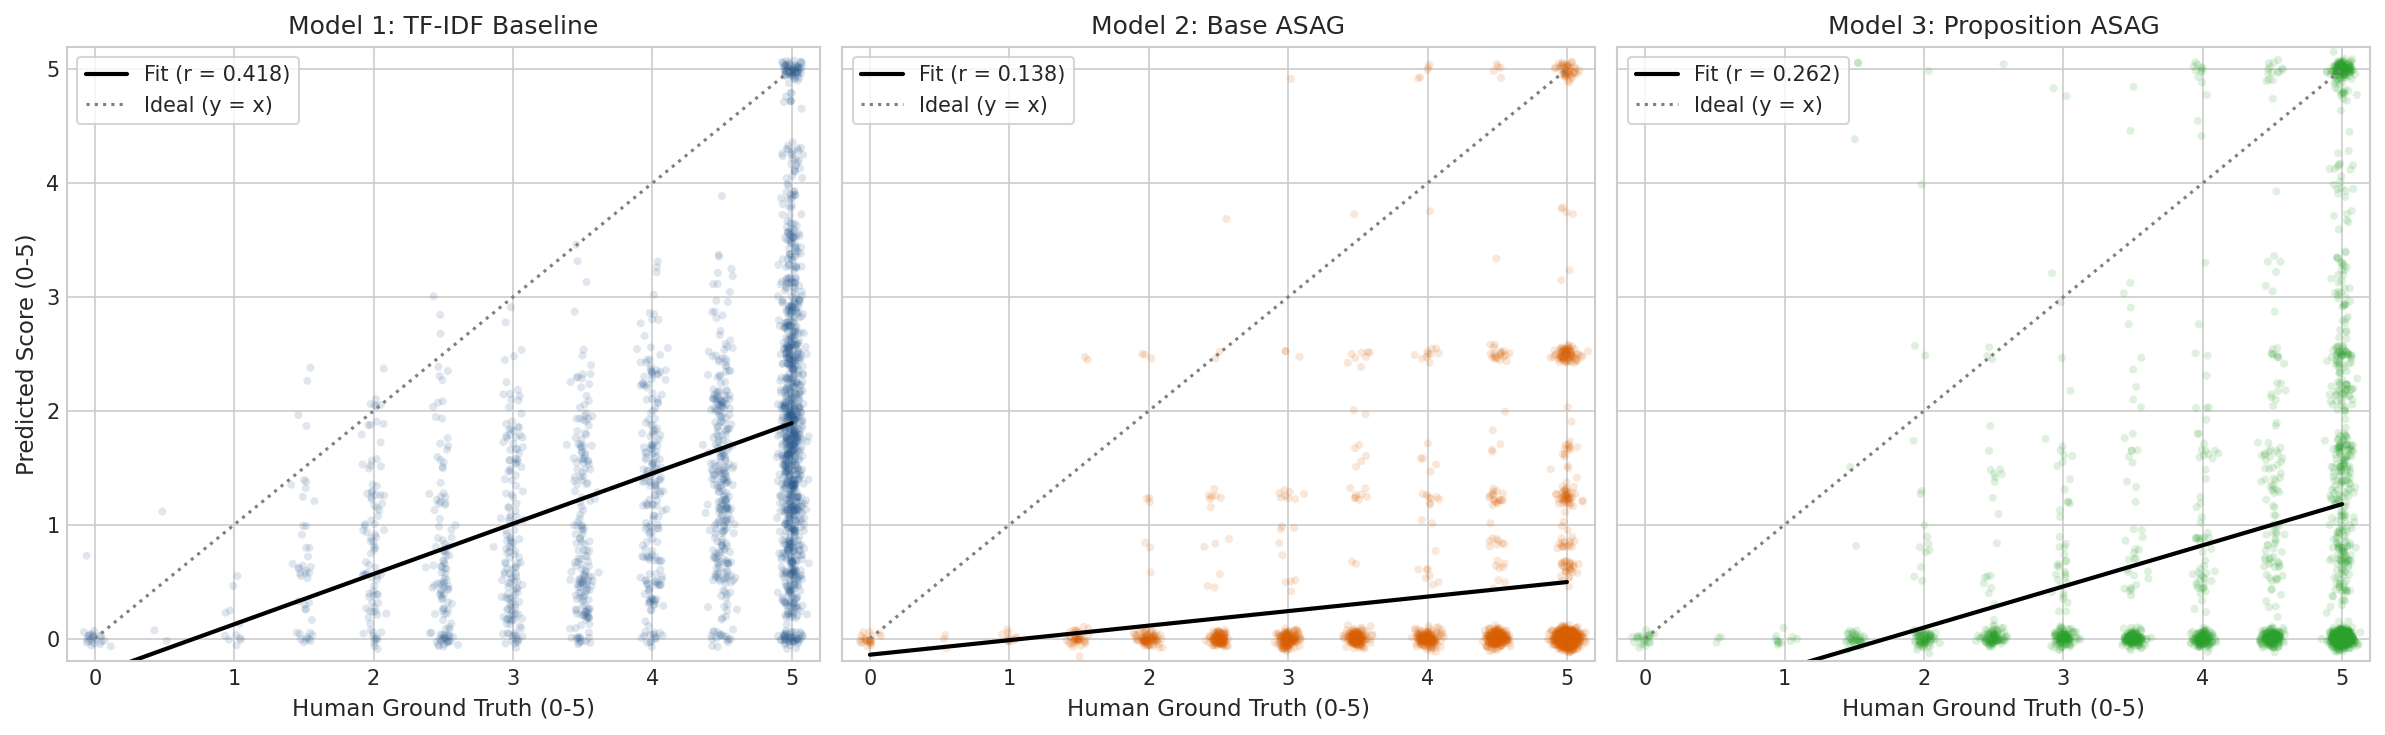

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

models = [
    ('Model 1: TF-IDF Baseline', df['v0_grade'], '#2b5c8f', axes[0]),
    ('Model 2: Base ASAG', df['v1_grade'], '#d95f02', axes[1]),
    ('Model 3: Proposition ASAG', df['v5_full_grade'], '#2ca02c', axes[2])
]

for title, pred, color, ax in models:
    # Jitter points slightly for visualization density
    jitter_x = df['human_score'] + np.random.normal(0, 0.04, size=len(df))
    jitter_y = pred + np.random.normal(0, 0.04, size=len(df))
    
    ax.scatter(jitter_x, jitter_y, alpha=0.15, s=15, color=color, edgecolors='none')
    
    # Regression trendline
    slope, intercept, r_val, p_val, std_err = stats.linregress(df['human_score'], pred)
    x_vals = np.array([0, 5])
    ax.plot(x_vals, intercept + slope * x_vals, color='black', lw=2, linestyle='-', label=f'Fit (r = {r_val:.3f})')
    
    # Perfect calibration reference line
    ax.plot([0, 5], [0, 5], color='gray', lw=1.5, linestyle=':', label='Ideal (y = x)')
    
    ax.set_title(title)
    ax.set_xlabel('Human Ground Truth (0-5)')
    ax.set_xlim(-0.2, 5.2)
    ax.set_ylim(-0.2, 5.2)
    ax.legend(loc='upper left', frameon=True)

axes[0].set_ylabel('Predicted Score (0-5)')
plt.tight_layout()
plt.show()

## 7. Calibration & Reliability Curves

In educational evaluation, a calibrated model should predict progressively higher scores as human ratings increase. We partition student answers into five human score bins ($[0-1, 1-2, 2-3, 3-4, 4-5]$) and calculate the average prediction within each bin.

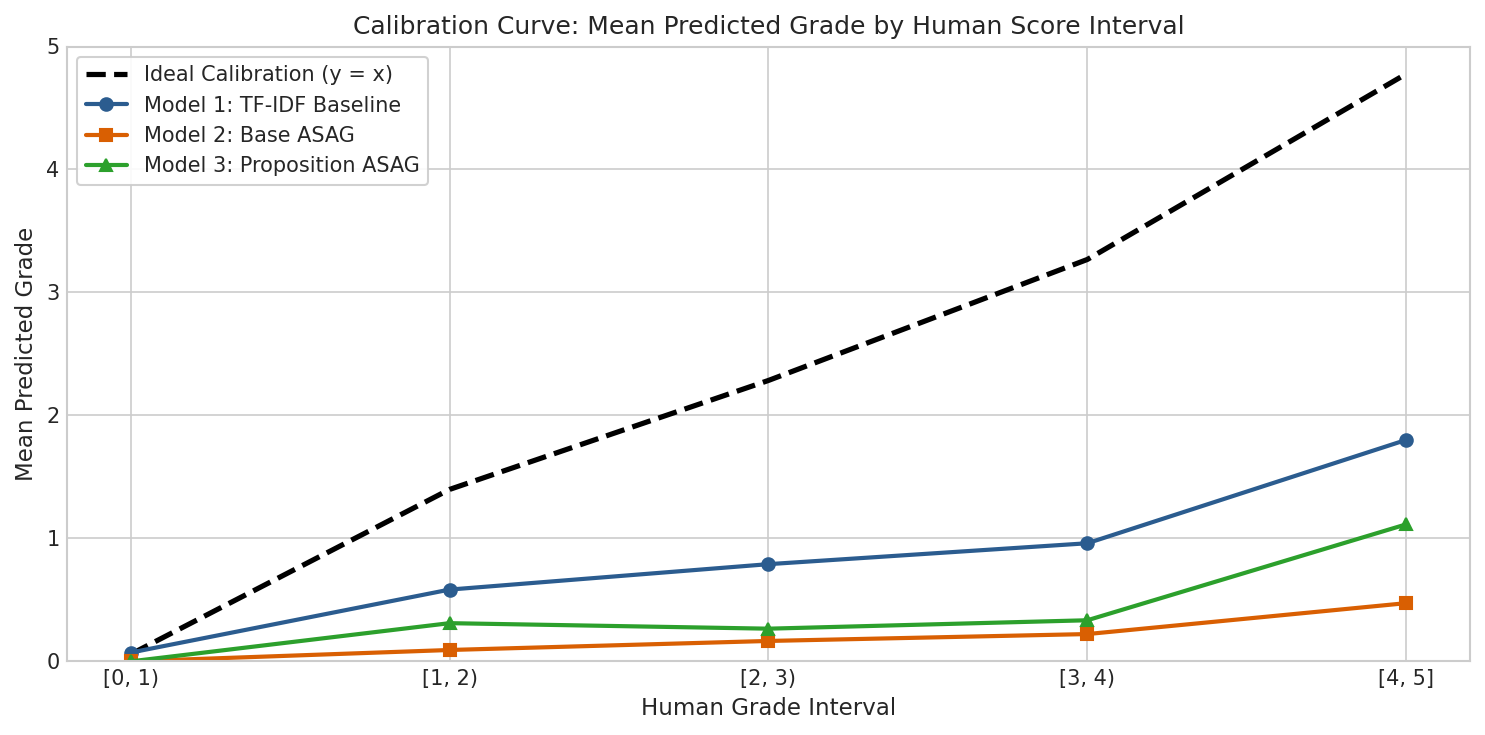

Calibration Table (Mean Predicted Score by Human Grade Bin):


,v0_grade,v1_grade,v5_full_grade,human_score
human_bin,,,,
"[0, 1)",0.071,0.000,0.000,0.058
"[1, 2)",0.584,0.093,0.311,1.398
"[2, 3)",0.791,0.166,0.266,2.284
"[3, 4)",0.961,0.222,0.334,3.268
"[4, 5]",1.801,0.473,1.114,4.777


In [7]:
bins = [0.0, 1.0, 2.0, 3.0, 4.0, 5.01]
bin_labels = ['[0, 1)', '[1, 2)', '[2, 3)', '[3, 4)', '[4, 5]']
df['human_bin'] = pd.cut(df['human_score'], bins=bins, labels=bin_labels, right=False)

calib_df = df.groupby('human_bin', observed=False)[['v0_grade', 'v1_grade', 'v5_full_grade', 'human_score']].mean()

plt.figure(figsize=(10, 5))
bin_centers = [0.5, 1.5, 2.5, 3.5, 4.5]

plt.plot(bin_centers, calib_df['human_score'], 'k--', label='Ideal Calibration (y = x)', lw=2.5)
plt.plot(bin_centers, calib_df['v0_grade'], 'o-', color='#2b5c8f', lw=2, label='Model 1: TF-IDF Baseline')
plt.plot(bin_centers, calib_df['v1_grade'], 's-', color='#d95f02', lw=2, label='Model 2: Base ASAG')
plt.plot(bin_centers, calib_df['v5_full_grade'], '^-', color='#2ca02c', lw=2, label='Model 3: Proposition ASAG')

plt.title('Calibration Curve: Mean Predicted Grade by Human Score Interval')
plt.xlabel('Human Grade Interval')
plt.ylabel('Mean Predicted Grade')
plt.xticks(bin_centers, bin_labels)
plt.ylim(0, 5)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()

print("Calibration Table (Mean Predicted Score by Human Grade Bin):")
display(calib_df.round(3))

## 8. Subgroup Performance: Sentential vs. Non-Sentential References

A fundamental architectural insight from our investigation is the impact of reference answer syntax:
- **Sentential References ($N = 1,341$, 48 questions):** Reference answer contains a finite clausal structure.
- **Non-Sentential References ($N = 932$, 33 questions):** Reference answer is a nominal fragment, infinitive phrase, or definition.

As shown below, Model 2 (Base ASAG) fails completely on non-sentential references ($r = 0.0000$), because it cannot extract subject-predicate-object triples from non-finite phrases. Model 3 resolves this flaw via canonical fragment extraction, achieving $r = 0.2295$.

MAE  \
Subset              Non-Sentential References (N=932)   
Model                                                   
Model 1 (TF-IDF)                               2.5286   
Model 2 (Base ASAG)                            4.1668   
Model 3 (Prop ASAG)                            3.1687   

                                                    \
Subset              Sentential References (N=1341)   
Model                                                
Model 1 (TF-IDF)                            2.7464   
Model 2 (Base ASAG)                         3.5520   
Model 3 (Prop ASAG)                         3.4520   

                                            Pearson r  \
Subset              Non-Sentential References (N=932)   
Model                                                   
Model 1 (TF-IDF)                               0.4681   
Model 2 (Base ASAG)                            0.0000   
Model 3 (Prop ASAG)                            0.2985   

                                                    \
Subset              Sentential References (N=1341)   
Model                                                
Model 1 (TF-IDF)                            0.3743   
Model 2 (Base ASAG)                         0.1975   
Model 3 (Prop ASAG)                         0.2278   

                                         Spearman rho  \
Subset              Non-Sentential References (N=932)   
Model                                                   
Model 1 (TF-IDF)                               0.5342   
Model 2 (Base ASAG)                            0.0000   
Model 3 (Prop ASAG)                            0.3383   

                                                    
Subset              Sentential References (N=1341)  
Model                                               
Model 1 (TF-IDF)                            0.3591  
Model 2 (Base ASAG)                         0.1968  
Model 3 (Prop ASAG)                         0.2369

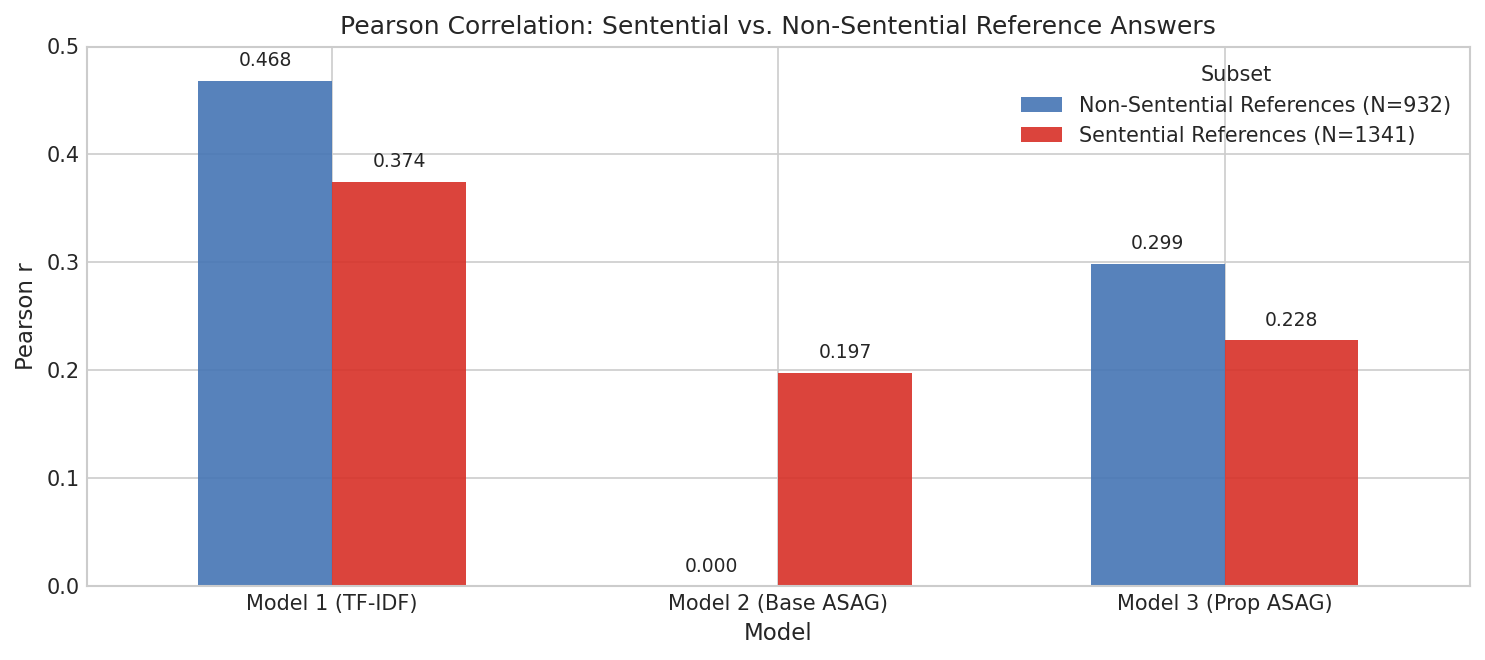

In [8]:
subgroup_results = []

for is_non_sent in [False, True]:
    subset_df = df[df['has_non_sentential_ref'] == is_non_sent]
    subset_name = "Non-Sentential References (N=932)" if is_non_sent else "Sentential References (N=1341)"
    
    for model_name, col in [('Model 1 (TF-IDF)', 'v0_grade'), 
                             ('Model 2 (Base ASAG)', 'v1_grade'), 
                             ('Model 3 (Prop ASAG)', 'v5_full_grade')]:
        m = compute_asag_metrics(subset_df['human_score'], subset_df[col])
        subgroup_results.append({
            'Subset': subset_name,
            'Model': model_name,
            'MAE': m['MAE'],
            'RMSE': m['RMSE'],
            'Pearson r': m['Pearson r'],
            'Spearman rho': m['Spearman rho'],
            'Pred Mean': m['Predicted Mean']
        })

subgroup_df = pd.DataFrame(subgroup_results)
display(subgroup_df.pivot(index='Model', columns='Subset', values=['MAE', 'Pearson r', 'Spearman rho']).round(4))

# Visualize Pearson Correlation across Subgroups
fig, ax = plt.subplots(figsize=(10, 4.5))
pivot_r = subgroup_df.pivot(index='Model', columns='Subset', values='Pearson r')
pivot_r.plot(kind='bar', ax=ax, color=['#4575b4', '#d73027'], width=0.6, alpha=0.9)
ax.set_title('Pearson Correlation: Sentential vs. Non-Sentential Reference Answers')
ax.set_ylabel('Pearson r')
ax.set_ylim(0, 0.5)
ax.set_xticklabels(pivot_r.index, rotation=0)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2., p.get_height() + 0.01),
                ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

## 9. Subgroup Performance: Coursework Assignments vs. Examinations

We compare performance between:
- **Assignments 1–10 ($N = 1,798$):** Targeted, modular homework questions.
- **Examinations ($N = 475$):** Midterm and final exam questions requiring synthetic explanations.

In [9]:
is_exam = df['assignment'].astype(str).isin(['11', '12'])
df['is_exam'] = is_exam

exam_results = []
for exam_flag in [False, True]:
    subset_df = df[df['is_exam'] == exam_flag]
    subset_name = "Exams (N=475)" if exam_flag else "Assignments 1-10 (N=1798)"
    
    for model_name, col in [('Model 1 (TF-IDF)', 'v0_grade'), 
                             ('Model 2 (Base ASAG)', 'v1_grade'), 
                             ('Model 3 (Prop ASAG)', 'v5_full_grade')]:
        m = compute_asag_metrics(subset_df['human_score'], subset_df[col])
        exam_results.append({
            'Subset': subset_name,
            'Model': model_name,
            'MAE': m['MAE'],
            'Pearson r': m['Pearson r'],
            'Spearman rho': m['Spearman rho']
        })

exam_df = pd.DataFrame(exam_results)
display(exam_df.pivot(index='Model', columns='Subset', values=['MAE', 'Pearson r', 'Spearman rho']).round(4))

MAE                \
Subset              Assignments 1-10 (N=1798) Exams (N=475)   
Model                                                         
Model 1 (TF-IDF)                       2.6472        2.6877   
Model 2 (Base ASAG)                    3.8019        3.8111   
Model 3 (Prop ASAG)                    3.3491        3.2944   

                                    Pearson r                \
Subset              Assignments 1-10 (N=1798) Exams (N=475)   
Model                                                         
Model 1 (TF-IDF)                       0.4177        0.4240   
Model 2 (Base ASAG)                    0.1336        0.1496   
Model 3 (Prop ASAG)                    0.2592        0.2682   

                                 Spearman rho                
Subset              Assignments 1-10 (N=1798) Exams (N=475)  
Model                                                        
Model 1 (TF-IDF)                       0.4451        0.4338  
Model 2 (Base ASAG)                    0.1227        0.1097  
Model 3 (Prop ASAG)                    0.2871        0.2545

## 10. Ablation Discussion: The Epistemic Role of Additional Information

A pivotal goal of this project was to determine whether evaluating unmatched student propositions improves grading agreement.

In our Task 8 ablation study, we compared:
- **`V5_Core_Only`:** Model 3 grading strictly from reference requirement coverage (core paraphrase alignment and positive contradiction checks).
- **`V5_Full`:** Model 3 with the full four-way proposition classification and scoring layer active.

### Verified Ablation Metrics ($N = 2,273$):
- **Core-Only:** $\text{MAE} = 3.3319$, $\text{Pearson } r = 0.2625$, $\text{Spearman } \rho = 0.2824$, $\text{QWK} = 0.0619$
- **Full Model 3:** $\text{MAE} = 3.3358$, $\text{Pearson } r = 0.2616$, $\text{Spearman } \rho = 0.2820$, $\text{QWK} = 0.0615$

### Research Takeaway:
Evaluating unmatched student propositions as additional information **does not improve agreement with human graders** on the Mohler benchmark. 

In undergraduate examinations, instructors grade according to strict rubrics focusing on whether essential requirements are met. Additional correct facts do not award bonus points above the maximum score, while irrelevant or unverified assertions are treated neutrally unless they introduce direct contradictions. The primary value of proposition-level analysis lies in **interpretability, diagnostic explanation, and educational feedback**, rather than raw correlation gains.

## 11. Qualitative Case Studies from Genuine Benchmark Records

We inspect representative answers from the dataset to examine model grading behavior.

In [10]:
def inspect_record(qid, student_idx=None):
    qid_str = str(qid).strip()
    if student_idx is not None:
        rec = df[(df['question_id'] == qid_str) & (df['student_index'] == int(student_idx))]
    else:
        rec = df[df['question_id'] == qid_str]
        
    if len(rec) == 0:
        print(f"Record {qid_str} not found.")
        return
        
    row = rec.iloc[0]
    print("="*80)
    print(f"QUESTION ID: {row['question_id']} | Assignment: {row['assignment']} | Student Index: {row['student_index']}")
    print(f"QUESTION:   {row['question_text']}")
    print(f"REFERENCE:  {row['reference_text']}")
    print(f"STUDENT:    {row['student_text']}")
    print("-" * 80)
    print(f"GRADES (Scale 0 - 5):")
    print(f"  Human Average:                          {row['human_score']:.2f}")
    print(f"  Model 1 (TF-IDF Baseline):              {row['v0_grade']:.2f}")
    print(f"  Model 2 (Base ASAG):                    {row['v1_grade']:.2f}")
    print(f"  Model 3 (Proposition ASAG):             {row['v5_full_grade']:.2f}")
    print("-" * 80)
    print(f"DIAGNOSTICS:")
    print(f"  Non-Sentential Reference:  {row['has_non_sentential_ref']}")
    print(f"  Recovered Core Paraphrases:{row['recovered_core_count']}")
    print(f"  Guarded Contradictions:    {row['guarded_contra_count']}")
    print(f"  Unmatched Classifications: Correct={row['correct_additional_count']}, Irrelevant={row['irrelevant_count']}, Incorrect={row['incorrect_count']}, Uncertain={row['uncertain_count']}")
    print("="*80 + "\n")

# Case 1: Q6.1 - Paraphrased definition of a pointer (Fixed in Task 8)
inspect_record('6.1', 0)

# Case 2: Q11.10 - Multi-clause explanation of merge sort
inspect_record('11.10', 0)

# Case 3: Q2.1 - Non-sentential reference fragment (Secondary cache)
inspect_record('2.1', 0)

QUESTION ID: 6.1 | Assignment: 6 | Student Index: 0
QUESTION:   What is a pointer?
REFERENCE:  A variable that contains the address in memory of another variable.
STUDENT:    Its a location in memory that contains the memory address of another location in memory that contains information.
--------------------------------------------------------------------------------
GRADES (Scale 0 - 5):
  Human Average:                          5.00
  Model 1 (TF-IDF Baseline):              2.77
  Model 2 (Base ASAG):                    2.50
  Model 3 (Proposition ASAG):             1.83
--------------------------------------------------------------------------------
DIAGNOSTICS:
  Non-Sentential Reference:  False
  Recovered Core Paraphrases:0
  Guarded Contradictions:    0
  Unmatched Classifications: Correct=0, Irrelevant=1, Incorrect=0, Uncertain=0

QUESTION ID: 11.10 | Assignment: 11 | Student Index: 0
QUESTION:   Briefly describe in one sentence how does merge sort work?
REFERENCE:  It splits 

## 12. Live Engine Execution Demonstration

We demonstrate how each grading engine is invoked directly via the project's model interfaces and pipeline registry on an illustrative test case.

In [1]:
from models.registry import ModelRegistry
from proposed_asag.pipeline_v5 import Experiment5Pipeline, Experiment5Variant

demo_question = "What is the purpose of a primary key?"
demo_reference = "A primary key uniquely identifies each record in a table."
demo_student = "A primary key uniquely identifies every row in a table and cannot contain NULL values."

print(f"Question:  {demo_question}")
print(f"Reference: {demo_reference}")
print(f"Student:   {demo_student}\n")

# 1. Model 1: TF-IDF Baseline
v0_model = ModelRegistry.get_model("V0", scale=5.0)
v0_result = v0_model.evaluate(demo_question, demo_reference, demo_student)
print(f"Model 1 (TF-IDF) Score:      {v0_result.grade:.3f} / 5.0")

# 2. Model 2: Base ASAG
v1_model = ModelRegistry.get_model("V1", scale=5.0)
v1_result = v1_model.evaluate(demo_question, demo_reference, demo_student)
print(f"Model 2 (Base ASAG) Score:   {v1_result.grade:.3f} / 5.0")

# 3. Model 3: Proposition ASAG
v5_pipeline = Experiment5Pipeline(variant=Experiment5Variant.V5, enable_additional_info=True)
v5_result = v5_pipeline.evaluate(demo_question, demo_reference, demo_student)
print(f"Model 3 (Prop ASAG) Score:   {v5_result.final_grade:.3f} / 5.0")

print("\nModel 3 Diagnostic Proposition Breakdown:")
print(f"  Reference Requirements:   {len(v5_result.reference_requirements)}")
for req in v5_result.reference_requirements:
    print(f"    - Requirement: '{req.reference_text}' --> Status: {req.status.value} (Method: {req.fulfillment_method})")

print(f"\nModel 3 Proposition Category Counts:")
for k, v in v5_result.counts.items():
    print(f"    - {k}: {v}")

Question:  What is the purpose of a primary key?
Reference: A primary key uniquely identifies each record in a table.
Student:   A primary key uniquely identifies every row in a table and cannot contain NULL values.

Model 1 (TF-IDF) Score:      2.742 / 5.0
Model 2 (Base ASAG) Score:   2.500 / 5.0
Model 3 (Prop ASAG) Score:   5.000 / 5.0

Model 3 Diagnostic Proposition Breakdown:
  Reference Requirements:   1
    - Requirement: 'key uniquely identifies each record' --> Status: SUPPORTED (Method: BASE_TRIPLE_MATCH)

Model 3 Proposition Category Counts:
    - total_ref_props: 1
    - total_stu_props: 2
    - matched_by_base: 1
    - recovered_core: 0
    - guarded_contradictions: 0
    - correct_additional: 1
    - incorrect: 0
    - irrelevant: 0
    - uncertain: 0


## 13. Summary of Findings & Research Takeaways

### Empirical Summary

| System | MAE $\downarrow$ | Pearson $r$ $\uparrow$ | Spearman $\rho$ $\uparrow$ | Key Strength | Key Architectural Limitation |
| :--- | :---: | :---: | :---: | :--- | :--- |
| **Model 1: TF-IDF Baseline** | **2.6571** | **0.4184** | **0.4424** | Robust to syntactic variation, broadest vocabulary coverage. | Opaque score, ignores negation and semantic roles, zero interpretability. |
| **Model 2: Base ASAG** | 3.8041 | 0.1383 | 0.1179 | High grammatical transparency for clausal triples. | Fails completely on 40.7% non-sentential reference fragments; severe underprediction. |
| **Model 3: Proposition ASAG** | 3.3358 | 0.2616 | 0.2820 | Canonical fragment recovery doubles Pearson over Model 2; granular epistemic explanations. | Additional info evaluation does not improve human agreement; still trails lexical baseline. |

### Research Conclusions:
1. **Linguistic Feasibility:** Proposition-level decomposition and four-way epistemic classification (`CORRECT_ADDITIONAL`, `IRRELEVANT`, `INCORRECT`, `UNCERTAIN`) is fully feasible and provides complete pedagogical interpretability.
2. **Grading Agreement:** Evaluating unmatched student propositions does **not** improve correlation with human grades over reference coverage alone. Human graders focus predominantly on core requirement presence.
3. **Primary Source of Structural Gains:** The substantial gains of Model 3 over Model 2 stem from **canonical reference extraction and generalized core paraphrase recovery**, not from additional-information modulation.

---
*Notebook completed for the AIES ASAG Undergraduate Research Project.*